# Brain MRI Tumor Classification — Final Model Comparison

**Notebook 4: Held-out test evaluation and deployment comparison**

This notebook compares the custom CNN, MobileNetV2, EfficientNetB0, and ResNet50 using the verified test rows from the dataset manifest. It does not train or fine-tune any model.


## Project context and evaluation rule

The saved model artifacts are loaded from the project's `Models` folder. Every model receives the same test images and labels, with the preprocessing used when that model was trained. We report accuracy, macro-F1, per-class precision/recall, confusion matrices, and saved model size.

**Important:** Notebook 2 already evaluated the custom CNN on the test split. Its test score has therefore already been observed. The results here are useful for a consistent comparison, but should not be described as a completely untouched final benchmark for that model. Use validation results and deployment constraints to choose a model; treat test metrics as a final report, not as the tuning or selection signal.

The 500 MB figure is treated as a model-artifact size target. The complete Streamlit app also includes code and dependencies, so its final deployed size must be checked separately.


## Notebook plan

1. Connect Google Drive and load libraries and project paths.
2. Read the manifest and keep only verified test rows.
3. Check that the four saved model files and class order are present.
4. Build one deterministic test-image pipeline and apply each model's required preprocessing.
5. Predict with each saved model and calculate comparable metrics.
6. Compare test results, validation results, and model sizes.
7. Save CSV, JSON, and confusion-matrix outputs in the project's `Evaluation` folder.


## Step 1 — Connect Drive, import libraries, and set paths

Set `DATASET_ROOT` to the same Datasets folder used in Notebooks 1–3. The manifest is directly inside that folder; models are in the sibling `Models` folder.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)

DATASET_ROOT = Path('/content/drive/MyDrive/Brain MRI Tumor Classification/Datasets')
PROJECT_ROOT = DATASET_ROOT.parent
MANIFEST_PATH = DATASET_ROOT / 'brain_mri_dataset_manifest.csv'
MODEL_DIR = PROJECT_ROOT / 'Models'
EVALUATION_DIR = PROJECT_ROOT / 'Evaluation'
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
CLASS_NAMES = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
NUM_CLASSES = len(CLASS_NAMES)
LABEL_TO_ID = {name: index for index, name in enumerate(CLASS_NAMES)}
AUTOTUNE = tf.data.AUTOTUNE

print('TensorFlow:', tf.__version__)
print('Manifest:', MANIFEST_PATH)
print('Models:', MODEL_DIR)
print('Evaluation outputs:', EVALUATION_DIR)
print('GPU devices:', tf.config.list_physical_devices('GPU'))


Mounted at /content/drive
TensorFlow: 2.21.0
Manifest: /content/drive/MyDrive/Brain MRI Tumor Classification/Datasets/brain_mri_dataset_manifest.csv
Models: /content/drive/MyDrive/Brain MRI Tumor Classification/Models
Evaluation outputs: /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation
GPU devices: []


## Step 2 — Load and verify the held-out test rows

We use the manifest created in Notebook 1. Only rows marked `label_verified` and assigned to the `test` split are included. We also confirm that every class is present and every referenced image path exists.


In [2]:
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(
        f'Manifest not found: {MANIFEST_PATH}. Check the Drive path and run Notebook 1.'
    )

manifest = pd.read_csv(MANIFEST_PATH)
required_columns = {'filepath', 'split', 'label', 'label_verified'}
missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(f'Manifest is missing columns: {sorted(missing_columns)}')

verified = manifest[
    manifest['label_verified'].astype(str).str.strip().str.lower().isin(['true', '1'])
    & manifest['filepath'].notna()
    & manifest['label'].notna()
].copy()
verified['filepath'] = verified['filepath'].astype(str).str.strip()
verified['label'] = verified['label'].astype(str).str.strip()
test_df = verified[verified['split'].astype(str).str.strip().str.lower() == 'test'].copy()

unknown_labels = sorted(set(test_df['label']) - set(CLASS_NAMES))
if unknown_labels:
    raise ValueError(f'Unexpected test labels: {unknown_labels}')
if test_df.empty:
    raise ValueError('No verified rows were found for the test split.')

missing_files = [path for path in test_df['filepath'] if not Path(path).is_file()]
if missing_files:
    raise FileNotFoundError(
        f'{len(missing_files)} test image paths do not exist. Example: {missing_files[0]}'
    )

test_df = test_df.reset_index(drop=True)
y_true = test_df['label'].map(LABEL_TO_ID).to_numpy(dtype=np.int32)
class_counts = test_df['label'].value_counts().reindex(CLASS_NAMES, fill_value=0)
if (class_counts == 0).any():
    raise ValueError(f'Test split is missing one or more classes: {class_counts.to_dict()}')

print(f'Verified test images: {len(test_df):,}')
display(class_counts.rename('test images').to_frame())


Verified test images: 246


,test images
label,
Glioma,80
Meningioma,63
No Tumor,49
Pituitary,54


## Step 3 — Locate model artifacts and check class order

The filenames below match the save locations from Notebooks 2 and 3. The pretrained model index also records the class order and each model's validation summary.


In [3]:
CLASS_NAMES_PATH = MODEL_DIR / 'class_names.json'
CUSTOM_SUMMARY_PATH = MODEL_DIR / 'custom_cnn_evaluation_summary.json'
PRETRAINED_INDEX_PATH = MODEL_DIR / 'pretrained_model_index.json'

MODEL_PATHS = {
    'Custom CNN': MODEL_DIR / 'brain_mri_custom_cnn_final.keras',
    'MobileNetV2': MODEL_DIR / 'mobilenetv2_best_validation.keras',
    'EfficientNetB0': MODEL_DIR / 'efficientnetb0_best_validation.keras',
    'ResNet50': MODEL_DIR / 'resnet50_best_validation.keras',
}

missing_paths = [str(path) for path in MODEL_PATHS.values() if not path.is_file()]
if missing_paths:
    raise FileNotFoundError(
        'These model files are missing. Confirm that Notebooks 2 and 3 completed and saved them:\n'
        + '\n'.join(missing_paths)
    )
if CLASS_NAMES_PATH.is_file():
    saved_class_names = json.loads(CLASS_NAMES_PATH.read_text(encoding='utf-8'))
    if saved_class_names != CLASS_NAMES:
        raise ValueError(
            f'Class order mismatch. Notebook 4 expects {CLASS_NAMES}, got {saved_class_names}.'
        )
if not PRETRAINED_INDEX_PATH.is_file():
    raise FileNotFoundError(
        f'Pretrained model index not found: {PRETRAINED_INDEX_PATH}. Re-run the final cell of Notebook 3.'
    )

pretrained_index = json.loads(PRETRAINED_INDEX_PATH.read_text(encoding='utf-8'))
if pretrained_index.get('class_names_in_output_order') != CLASS_NAMES:
    raise ValueError('The pretrained model index has a different output class order.')
for model_key in ['mobilenetv2', 'efficientnetb0', 'resnet50']:
    if model_key not in pretrained_index.get('models', {}):
        raise ValueError(f'{model_key} is missing from pretrained_model_index.json.')

print('All four model files are present.')
for display_name, path in MODEL_PATHS.items():
    print(f'{display_name}: {path.name} ({path.stat().st_size / (1024 ** 2):.2f} MB)')


All four model files are present.
Custom CNN: brain_mri_custom_cnn_final.keras (1.35 MB)
MobileNetV2: mobilenetv2_best_validation.keras (20.76 MB)
EfficientNetB0: efficientnetb0_best_validation.keras (33.77 MB)
ResNet50: resnet50_best_validation.keras (204.80 MB)


## Step 4 — Create a consistent test image pipeline

Images are resized to 224 × 224 RGB and left in the 0–255 range at first. MobileNetV2 and ResNet50 then receive their Keras application preprocessing; EfficientNetB0 receives raw float RGB values because its Keras model includes preprocessing internally. The custom CNN expects raw pixel values and rescales them inside the saved model.


In [4]:
def load_and_resize_image(filepath):
    image_bytes = tf.io.read_file(filepath)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)  # float RGB pixels in [0, 255]
    return image

raw_test_ds = (
    tf.data.Dataset.from_tensor_slices(test_df['filepath'].astype(str).to_numpy())
    .map(load_and_resize_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

PREPROCESSING = {
    'Custom CNN': lambda image: image,
    'MobileNetV2': tf.keras.applications.mobilenet_v2.preprocess_input,
    'EfficientNetB0': lambda image: image,
    'ResNet50': tf.keras.applications.resnet50.preprocess_input,
}

def make_test_dataset(model_name):
    preprocessing_fn = PREPROCESSING[model_name]
    return raw_test_ds.map(
        lambda image: preprocessing_fn(image),
        num_parallel_calls=AUTOTUNE,
    )

print('Test image pipeline is ready; test rows remain in manifest order.')


Test image pipeline is ready; test rows remain in manifest order.


## Step 5 — Run predictions and calculate comparable metrics

Each saved model is loaded without its training optimizer, predicts on the same ordered test images, and is released from memory before the next model loads. We calculate aggregate metrics and a separate per-class report for each model.


In [5]:
MODEL_NAME_TO_KEY = {
    'MobileNetV2': 'mobilenetv2',
    'EfficientNetB0': 'efficientnetb0',
    'ResNet50': 'resnet50',
}

test_metric_rows = []
per_class_rows = []
confusion_matrices = {}

for model_name, model_path in MODEL_PATHS.items():
    print(f'\nEvaluating {model_name}...')
    tf.keras.backend.clear_session()
    model = tf.keras.models.load_model(model_path, compile=False)
    probabilities = model.predict(make_test_dataset(model_name), verbose=1)
    if probabilities.shape != (len(test_df), NUM_CLASSES):
        raise ValueError(
            f'{model_name} returned shape {probabilities.shape}; expected '
            f'({len(test_df)}, {NUM_CLASSES}). Check model output classes and test pipeline.'
        )
    y_pred = probabilities.argmax(axis=1)
    matrix = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    report = classification_report(
        y_true, y_pred, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES,
        output_dict=True, zero_division=0,
    )
    confusion_matrices[model_name] = matrix
    test_metric_rows.append({
        'model': model_name,
        'test_accuracy': float(accuracy_score(y_true, y_pred)),
        'test_macro_precision': float(precision_score(
            y_true, y_pred, average='macro', zero_division=0)),
        'test_macro_recall': float(recall_score(
            y_true, y_pred, average='macro', zero_division=0)),
        'test_macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
        'test_weighted_f1': float(f1_score(y_true, y_pred, average='weighted', zero_division=0)),
        'model_size_mb': float(model_path.stat().st_size / (1024 ** 2)),
        'model_path': str(model_path),
    })
    for class_name in CLASS_NAMES:
        per_class_rows.append({
            'model': model_name,
            'class': class_name,
            'precision': report[class_name]['precision'],
            'recall': report[class_name]['recall'],
            'f1_score': report[class_name]['f1-score'],
            'support': int(report[class_name]['support']),
        })
    del model, probabilities, y_pred
    gc.collect()

test_metrics = pd.DataFrame(test_metric_rows).sort_values(
    'test_macro_f1', ascending=False
).reset_index(drop=True)
per_class_metrics = pd.DataFrame(per_class_rows)
display(test_metrics.drop(columns='model_path').round(4))



Evaluating Custom CNN...
8/8 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step

Evaluating MobileNetV2...
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step

Evaluating EfficientNetB0...


8/8 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step

Evaluating ResNet50...


8/8 ━━━━━━━━━━━━━━━━━━━━ 53s 6s/step


,model,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1,model_size_mb
0,ResNet50,0.9350,0.9345,0.9283,0.9292,0.9344,204.7960
1,MobileNetV2,0.8699,0.8755,0.8698,0.8664,0.8691,20.7610
2,EfficientNetB0,0.8333,0.8430,0.8389,0.8340,0.8328,33.7728
3,Custom CNN,0.6626,0.7227,0.6713,0.6465,0.6541,1.3539


## Step 6 — Visualize and save per-model confusion matrices

Rows in each matrix are the true classes and columns are the predicted classes, in the fixed class order shown below. These plots make class-specific errors easier to inspect than one overall accuracy score.


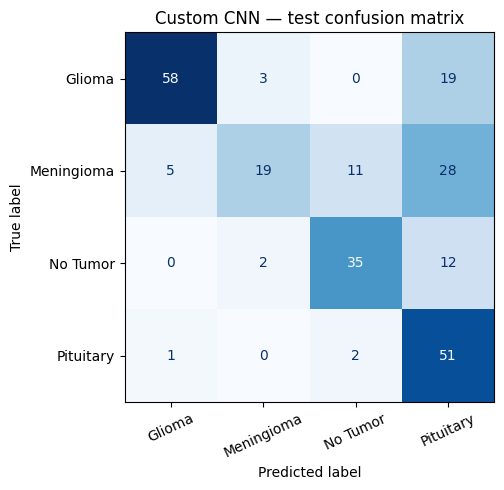

Saved: /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation/custom_cnn_test_confusion_matrix.png


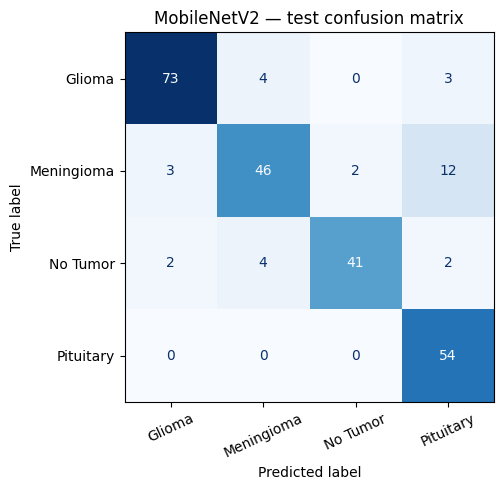

Saved: /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation/mobilenetv2_test_confusion_matrix.png


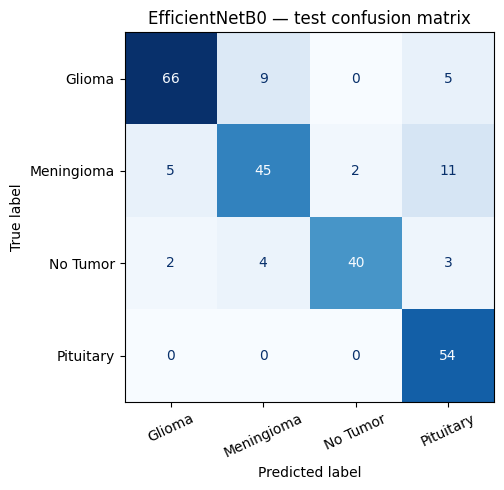

Saved: /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation/efficientnetb0_test_confusion_matrix.png


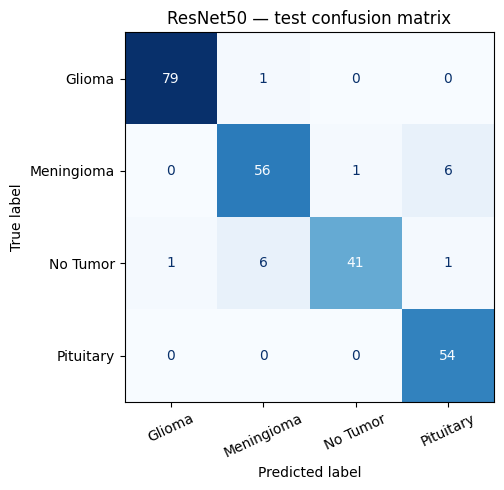

Saved: /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation/resnet50_test_confusion_matrix.png


In [6]:
for model_name, matrix in confusion_matrices.items():
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=CLASS_NAMES
    ).plot(ax=ax, cmap='Blues', values_format='d', xticks_rotation=25, colorbar=False)
    ax.set_title(f'{model_name} — test confusion matrix')
    fig.tight_layout()
    output_path = EVALUATION_DIR / f'{model_name.lower().replace(" ", "_")}_test_confusion_matrix.png'
    fig.savefig(output_path, dpi=160, bbox_inches='tight')
    plt.show()
    print('Saved:', output_path)


## Step 7 — Compare validation results and deployment artifact sizes

This table combines validation metrics saved during training with the model file sizes and the test report. The deployment shortlist is based on **validation accuracy**: models within 5 percentage points of the best validation accuracy are considered close enough for the user's stated size preference, then the smallest model is shown first. Test metrics are displayed for reporting only and are not used to select the shortlist.

`under_500_mb` checks only the saved model artifact, not the full Streamlit app bundle.


In [7]:
if not CUSTOM_SUMMARY_PATH.is_file():
    raise FileNotFoundError(
        f'Custom CNN summary not found: {CUSTOM_SUMMARY_PATH}. Re-run Notebook 2 final save cell.'
    )
custom_summary = json.loads(CUSTOM_SUMMARY_PATH.read_text(encoding='utf-8'))
validation_rows = [{
    'model': 'Custom CNN',
    'validation_accuracy': float(custom_summary['validation_accuracy']),
    'validation_macro_f1': float(custom_summary['validation_macro_f1']),
}]
for display_name, model_key in MODEL_NAME_TO_KEY.items():
    item = pretrained_index['models'][model_key]
    validation_rows.append({
        'model': display_name,
        'validation_accuracy': float(item['validation_accuracy']),
        'validation_macro_f1': float(item['validation_macro_f1']),
    })

validation_comparison = pd.DataFrame(validation_rows)
comparison = (
    validation_comparison
    .merge(test_metrics.drop(columns='model_path'), on='model', how='inner')
)
if len(comparison) != len(MODEL_PATHS):
    raise ValueError('Could not match every model across validation and test comparison tables.')
best_validation_accuracy = comparison['validation_accuracy'].max()
comparison['within_5pp_of_best_validation_accuracy'] = (
    comparison['validation_accuracy'] >= best_validation_accuracy - 0.05
)
comparison['under_500_mb'] = comparison['model_size_mb'] < 500
comparison['shortlist_by_validation_and_size'] = (
    comparison['within_5pp_of_best_validation_accuracy'] & comparison['under_500_mb']
)
comparison = comparison.sort_values(
    ['shortlist_by_validation_and_size', 'model_size_mb', 'validation_accuracy'],
    ascending=[False, True, False],
).reset_index(drop=True)
display(comparison.round(4))

shortlist = comparison[comparison['shortlist_by_validation_and_size']]
if shortlist.empty:
    print('No model meets both the validation-accuracy tolerance and the 500 MB artifact target.')
else:
    print('Validation-and-size shortlist, smallest artifact first:')
    display(shortlist[['model', 'validation_accuracy', 'validation_macro_f1',
                       'model_size_mb', 'test_accuracy', 'test_macro_f1']].round(4))
print('Use class-level recall and the intended deployment constraints in the final decision too.')


,model,validation_accuracy,validation_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1,model_size_mb,within_5pp_of_best_validation_accuracy,under_500_mb,shortlist_by_validation_and_size
0,ResNet50,0.9422,0.9393,0.9350,0.9345,0.9283,0.9292,0.9344,204.7960,True,True,True
1,Custom CNN,0.7311,0.7171,0.6626,0.7227,0.6713,0.6465,0.6541,1.3539,False,True,False
2,MobileNetV2,0.8865,0.8817,0.8699,0.8755,0.8698,0.8664,0.8691,20.7610,False,True,False
3,EfficientNetB0,0.8386,0.8314,0.8333,0.8430,0.8389,0.8340,0.8328,33.7728,False,True,False


Validation-and-size shortlist, smallest artifact first:


,model,validation_accuracy,validation_macro_f1,model_size_mb,test_accuracy,test_macro_f1
0,ResNet50,0.9422,0.9393,204.796,0.935,0.9292


Use class-level recall and the intended deployment constraints in the final decision too.


## Step 8 — Save evaluation tables and summary

The output files are saved to the project's `Evaluation` folder on Google Drive so they can be used in the report or app-selection discussion.


In [8]:
test_metrics_path = EVALUATION_DIR / 'test_model_comparison.csv'
per_class_path = EVALUATION_DIR / 'test_per_class_metrics.csv'
comparison_path = EVALUATION_DIR / 'validation_test_size_comparison.csv'
summary_path = EVALUATION_DIR / 'final_model_evaluation_summary.json'

test_metrics.to_csv(test_metrics_path, index=False)
per_class_metrics.to_csv(per_class_path, index=False)
comparison.to_csv(comparison_path, index=False)

summary = {
    'project': 'Brain MRI Tumor Classification',
    'test_split_rows': int(len(test_df)),
    'class_names_in_output_order': CLASS_NAMES,
    'image_size': list(IMAGE_SIZE),
    'test_split_used_for_training_or_tuning_in_this_notebook': False,
    'custom_cnn_test_was_already_evaluated_in_notebook_2': True,
    'model_selection_rule': (
        'Use validation accuracy within 5 percentage points of the best; among those under the 500 MB model-artifact target, prefer smaller size. '
        'Test metrics are reported but not used for selection.'
    ),
    'models': test_metrics.to_dict(orient='records'),
    'outputs': {
        'test_comparison_csv': str(test_metrics_path),
        'per_class_metrics_csv': str(per_class_path),
        'validation_test_size_comparison_csv': str(comparison_path),
        'confusion_matrix_directory': str(EVALUATION_DIR),
    },
}
summary_path.write_text(json.dumps(summary, indent=2), encoding='utf-8')

print('Saved evaluation artifacts:')
for path in [test_metrics_path, per_class_path, comparison_path, summary_path]:
    print(' -', path)
print('Confusion matrices saved under:', EVALUATION_DIR)


Saved evaluation artifacts:
 - /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation/test_model_comparison.csv
 - /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation/test_per_class_metrics.csv
 - /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation/validation_test_size_comparison.csv
 - /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation/final_model_evaluation_summary.json
Confusion matrices saved under: /content/drive/MyDrive/Brain MRI Tumor Classification/Evaluation


## Final review

Before selecting a model for the Streamlit app, review validation accuracy and macro-F1, test accuracy and macro-F1, per-class recall, and model artifact size together. The shortlist is a decision aid based on validation metrics and the stated 5 percentage-point accuracy tolerance. Confirm that the complete app bundle—not just the model file—fits the deployment platform's current limit.

This educational classifier is not a medical diagnostic tool.
